In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.widgets as mwidgets
import matplotlib.path as mpath
import numpy as np
import matplotlib.path as mpath

In [8]:
%matplotlib widget

# the map df:

## burial_tables df:

In [9]:

file_path = "/Users/evijonas/python/archyviz/notebooks/final_project/archy494data_burialcoords(1).xlsx"

#create 'burial_tables' df
burial_tables = pd.read_excel(
    file_path,
    sheet_name="burialtables",
    skiprows=2
)

burial_tables.columns = (
    burial_tables.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

#clean & pivot wide
df = burial_tables.copy()
s = df["site"].astype(str)

is_subadult_marker = s.str.contains("Subadult", case=False, na=False)
df["age_group"] = np.where(is_subadult_marker.cumsum() > 0, "Subadult", "Adult")

bad_sites = {
    "Site",
    "Adults",
    "Subadults",
    "Table 1: Adult Burials",
    "Table 2: Subadult Burials"
}

df = df[~df["site"].isin(bad_sites)].copy()
df = df.dropna(subset=["site", "sub_region"])

df["total"] = pd.to_numeric(
    df["adult_burials"].replace({"-": 0}),
    errors="coerce"
)

df = df.dropna(subset=["total"])

wide = df.pivot_table(
    index=["site", "sub_region"],
    columns="age_group",
    values="total",
    aggfunc="sum"
)

wide = wide.reindex(columns=["Adult", "Subadult"])

#create 'totals' df
totals = (
    wide
    .rename(columns={"Adult": "adult_total", "Subadult": "subadult_total"})
    .reset_index()
)

totals[["adult_total", "subadult_total"]] = (
    totals[["adult_total", "subadult_total"]]
    .fillna(0)
    .astype(int)
)

totals.head()

#create 'analysis' df
burial_cols = [
    "intramural",
    "extramural",
    "pithos_burials",
    "simple_internment",
    "refuse_pit",
    "other",
]

burial_counts = burial_tables.copy()

bad_sites = {
    "Site",
    "Adults",
    "Subadults",
    "Table 1: Adult Burials",
    "Table 2: Subadult Burials"
}

burial_counts = burial_counts[~burial_counts["site"].isin(bad_sites)].copy()
burial_counts = burial_counts.dropna(subset=["site", "sub_region"])

burial_counts[burial_cols] = (
    burial_counts[burial_cols]
    .replace("-", 0)
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

burial_counts_by_site = (
    burial_counts
    .groupby("site", as_index=False)[burial_cols]
    .sum()
)

analysis_df = totals.merge(
    burial_counts_by_site,
    on="site",
    how="left"
)

analysis_df[burial_cols] = analysis_df[burial_cols].fillna(0)

/var/folders/v7/7vfbdgg12c39wdwbk95gjb000000gn/T/ipykernel_98335/615327494.py:37: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["adult_burials"].replace({"-": 0}),
/var/folders/v7/7vfbdgg12c39wdwbk95gjb000000gn/T/ipykernel_98335/615327494.py:92: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace("-", 0)


In [10]:
file_path = "/Users/evijonas/python/archyviz/notebooks/final_project/archy494data_burialcoords(1).xlsx"

geo_df = pd.read_excel(file_path, sheet_name=4)

geo_df.columns = (
    geo_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

#creating a merged dataframe (map coords and burial totals)
map_df = geo_df.merge(
    analysis_df[
        [
            "site",
            "adult_total",
            "subadult_total",
            "intramural",
            "extramural",
            "pithos_burials",
            "simple_internment",
            "refuse_pit",
            "other",
        ]
    ],
    on="site",
    how="left"
)

#finishing? the map_df
needed_cols = [
    "adult_total",
    "subadult_total",
    "intramural",
    "extramural",
    "pithos_burials",
    "simple_internment",
    "refuse_pit",
    "other"
]

map_df[needed_cols] = (
    map_df[needed_cols]
        .replace("-", 0)
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0)
)

#cleaning coords
map_df = map_df.dropna(subset=["latitude", "longitude"]).copy()

map_df[["adult_total", "subadult_total"]] = (
    map_df[["adult_total", "subadult_total"]]
    .fillna(0)
    .astype(int)
)

x = map_df["longitude"].to_numpy()
y = map_df["latitude"].to_numpy()
sites = map_df["site"].to_numpy()
adult_totals = map_df["adult_total"].to_numpy()
subadult_totals = map_df["subadult_total"].to_numpy()
xy = np.c_[x, y]

# the interface:

ToggleButtons(description='Show:', options=(('Correlation matrix', 'correlation'), ('Bar chart', 'bar')), valu…

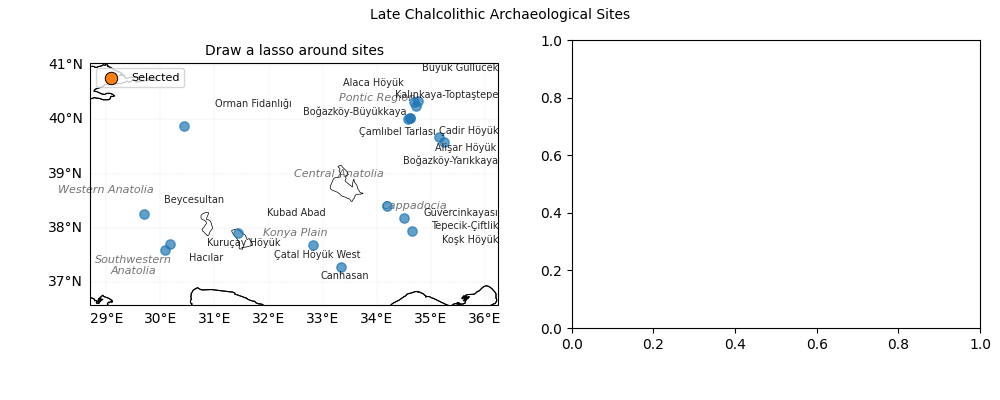

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import ipywidgets as widgets
from IPython.display import display
from adjustText import adjust_text
from matplotlib.patches import Polygon

# Data already prepared in map_df
x = map_df["longitude"].to_numpy()
y = map_df["latitude"].to_numpy()
sites = map_df["site"].to_numpy()
xy = np.c_[x, y]

# Geographic projection
projection = ccrs.PlateCarree()

# Map + bar chart layout
fig = plt.figure(figsize=(10, 4))

ax_map = fig.add_subplot(1, 2, 1, projection=projection)
ax_corr = fig.add_subplot(1, 2, 2)

fig.subplots_adjust(
    left=0.09,#######################
    right=0.98,
    bottom=0.18,
    top=0.90,
    wspace=0.18
)
fig.suptitle(
    "Late Chalcolithic Archaeological Sites",
    fontsize=10
)

# ---------------------------------------------------------
# BASEMAP
# ---------------------------------------------------------

# Set map extent slightly beyond the archaeological sites
padding_lon = 1.0
padding_lat = 0.7

ax_map.set_extent(
    [
        x.min() - padding_lon,
        x.max() + padding_lon,
        y.min() - padding_lat,
        y.max() + padding_lat
    ],
    crs=projection
)

# Land outline without a colored background
ax_map.add_feature(
    cfeature.LAND,
    facecolor="none",
    edgecolor="black",
    linewidth=0.7,
    zorder=0
)

# Coastlines
ax_map.coastlines(
    resolution="10m",
    linewidth=0.8,
    zorder=1
)

# Modern national boundaries, useful only as geographic reference
ax_map.add_feature(
    cfeature.BORDERS,
    linestyle=":",
    linewidth=0.5,
    alpha=0.5,
    zorder=1
)

# Lakes
ax_map.add_feature(
    cfeature.LAKES,
    facecolor="none",
    edgecolor="black",
    linewidth=0.5,
    zorder=1
)

# Longitude and latitude grid
gridlines = ax_map.gridlines(
    draw_labels=True,
    linewidth=0.3,
    linestyle="--",
    alpha=0.4
)

gridlines.top_labels = False
gridlines.right_labels = False

# ---------------------------------------------------------
# APPROXIMATE ANCIENT REGION LABELS
# ---------------------------------------------------------
# Coordinates are approximate label positions, not exact boundaries.

region_labels = {
    "Central Anatolia": (33.3, 39.0),
    "Western Anatolia": (29.0, 38.7),
    "Southwestern\nAnatolia": (29.5, 37.3),
    "Cappadocia": (34.7, 38.4),
    "Konya Plain": (32.5, 37.9),
    "Pontic Region": (34.0, 40.4),
}
    #changing to save regions so they don't overlap
region_texts = []

for region, (lon, lat) in region_labels.items():
    region_text = ax_map.text(
        lon,
        lat,
        region,
        transform=projection,
        ha="center",
        va="center",
        fontsize=8,
        fontstyle="italic",
        alpha=0.55,
        zorder=1
    )
    region_texts.append(region_text)

# ---------------------------------------------------------
# ARCHAEOLOGICAL SITES
# ---------------------------------------------------------

site_sc = ax_map.scatter(
    x,
    y,
    transform=projection,
    s=45,
    alpha=0.7,
    zorder=3,
    picker=5,  # allows clicks within 5 points of a site marker
)

# Tooltip shown when the cursor is over a site
hover_annotation = ax_map.annotate(
    "",
    xy=(0, 0),
    xytext=(12, 12),
    textcoords="offset points",
    transform=projection,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="black",
        alpha=0.9,
    ),
    arrowprops=dict(arrowstyle="->", color="black"),
    zorder=10,
)
hover_annotation.set_visible(False)

# Total burials at each site
burial_totals = (
    map_df["adult_total"].fillna(0)
    + map_df["subadult_total"].fillna(0)
).to_numpy()


def on_hover(event):
    if event.inaxes != ax_map:
        if hover_annotation.get_visible():
            hover_annotation.set_visible(False)
            fig.canvas.draw_idle()
        return

    contains, info = site_sc.contains(event)

    if contains:
        index = info["ind"][0]

        hover_annotation.xy = (x[index], y[index])
        hover_annotation.set_text(
            f"{sites[index]}\n"
            f"Total burials: {burial_totals[index]:.0f}"
        )
        hover_annotation.set_visible(True)
        fig.canvas.draw_idle()

    elif hover_annotation.get_visible():
        hover_annotation.set_visible(False)
        fig.canvas.draw_idle()


hover_connection = fig.canvas.mpl_connect(
    "motion_notify_event",
    on_hover,
)

selected_sc = ax_map.scatter(
    [],
    [],
    transform=projection,
    s=80,
    zorder=5,
    edgecolors="black",
    linewidths=0.7,
    label="Selected"
)

#---- adjusted (non overlapping) text
site_texts = []

for site, lon, lat in zip(sites, x, y):
    label = ax_map.text(
        lon,
        lat,
        site,
        transform=projection,
        fontsize=7,
        alpha=0.85,
        zorder=4
    )
    site_texts.append(label)

adjust_text(
    site_texts,
    ax=ax_map,
    x=x,
    y=y,
    expand=(1.15, 1.25),
    force_text=(0.4, 0.7),
    force_points=(0.3, 0.5),
)
#----

    #NOW
#---set up sites so the site labels and region label don't touch???
adjust_text(
    site_texts,
    ax=ax_map,
    x=x,
    y=y,
    objects=region_texts,
    expand=(1.08, 1.12),
    force_text=(0.2, 0.3),
    force_static=(0.4, 0.5)
)
#---

ax_map.set_title("Draw a lasso around sites", fontsize=10)
ax_map.legend(loc="upper left", fontsize=8)

# ---------------------------------------------------------
# BAR CHART
# ---------------------------------------------------------

# ---------------------------------------------------------
# CORRELATION HEATMAP
# ---------------------------------------------------------

corr_columns = [
    "adult_total",
    "subadult_total",
    "intramural",
    "extramural",
    "pithos_burials",
    "simple_internment",
    "refuse_pit",
    "other",
]

corr_labels = [
    "Adult",
    "Subadult",
    "Intramural",
    "Extramural",
    "Pithos",
    "Simple Internment",
    "Refuse Pit",
    "Other",
]
#-----
#Making widget to select different visualizations
#---
view_selector = widgets.ToggleButtons(
    options=[
        ("Correlation matrix", "correlation"),
        ("Bar chart", "bar"),
    ],
    value="correlation",
    description="Show:",
)

display(view_selector)

active_selection = {
    "indices": np.array([], dtype=int),
    "patch": None,
}

lasso_selections = {}

def draw_bar_chart(selected):
    ax_corr.set_aspect("auto")

    ratio_labels = [
        "Adult/\nSubadult",
        "Intramural/\nExtramural",
        "Pithos/\nOther",
        "Simple/\nOther",
        "Refuse pit/\nOther",
    ]

    def safe_ratio(numerator, denominator):
        return numerator / denominator if denominator != 0 else np.nan

    ratio_values = [
        safe_ratio(selected["adult_total"].sum(),
                   selected["subadult_total"].sum()),
        safe_ratio(selected["intramural"].sum(),
                   selected["extramural"].sum()),
        safe_ratio(selected["pithos_burials"].sum(),
                   selected["other"].sum()),
        safe_ratio(selected["simple_internment"].sum(),
                   selected["other"].sum()),
        safe_ratio(selected["refuse_pit"].sum(),
                   selected["other"].sum()),
    ]

    bars = ax_corr.bar(ratio_labels, ratio_values)

    finite_values = np.asarray(ratio_values, dtype=float)
    finite_values = finite_values[np.isfinite(finite_values)]
    upper_limit = max(1, finite_values.max() * 1.18) if len(finite_values) else 1

    ax_corr.set_ylim(0, upper_limit)
    ax_corr.set_title("Ratios for selected sites", fontsize=10)
    ax_corr.set_ylabel("Ratio (×)")
    ax_corr.tick_params(axis="x", rotation=30)

    for bar, value in zip(bars, ratio_values):
        label = "N/A" if np.isnan(value) else f"{value:.1f}×"
        y_position = upper_limit * 0.02 if np.isnan(value) else value

        ax_corr.text(
            bar.get_x() + bar.get_width() / 2,
            y_position,
            label,
            ha="center",
            va="bottom",
            fontsize=8,
        )


def draw_correlation_heatmap(selected):
    label_map = dict(zip(corr_columns, corr_labels))

    selected_corr = (
        selected[corr_columns]
        .corr()
        .rename(index=label_map, columns=label_map)
    )

    mask = np.triu(np.ones_like(selected_corr, dtype=bool))

    sns.heatmap(
        selected_corr,
        mask=mask,
        cmap="vlag",
        vmin=-1,
        vmax=1,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        linecolor="black",
        linewidths=0.5,
        square=True,
        cbar=False,
        ax=ax_corr,
    )

    ax_corr.set_title(
        f"Correlations: {len(selected)} selected sites",
        fontsize=10,
    )

    ax_corr.tick_params(axis="x", rotation=45)
    for label in ax_corr.get_xticklabels():
        label.set_horizontalalignment("right")


def show_selection(indices):
    active_selection["indices"] = indices
    ax_corr.clear()
    ax_corr.set_axis_on()

    if len(indices) < 2:
        selected_sc.set_offsets(np.empty((0, 2)))
        ax_corr.text(
            0.5, 0.5,
            "Select at least 2 sites",
            transform=ax_corr.transAxes,
            ha="center",
            va="center",
        )

    else:
        selected_sc.set_offsets(xy[indices])
        selected = map_df.iloc[indices]

        if view_selector.value == "correlation":
            draw_correlation_heatmap(selected)
        else:
            draw_bar_chart(selected)

    fig.canvas.draw_idle()
    
def change_view(change):
    if change["name"] == "value":
        show_selection(active_selection["indices"])

view_selector.observe(change_view, names="value")

def on_lasso(verts):
    path = mpath.Path(verts)
    indices = np.where(path.contains_points(xy))[0]

    patch = Polygon(
        verts,
        closed=True,
        facecolor="gold",
        edgecolor="crimson",
        alpha=0.20,
        linewidth=2,
        transform=projection,
        zorder=4,
        picker=True,
    )

    ax_map.add_patch(patch)
    lasso_selections[patch] = indices

    active_selection["patch"] = patch

    show_selection(indices)

    ax_map.add_patch(patch)
    lasso_selections[patch] = indices

    show_selection(indices)

def on_pick(event):
    # Left-click a site to add it to the active selection.
    if event.artist is site_sc:
        if event.mouseevent.button != 3:
            return  # only right-clicks add/remove sites

        clicked_index = event.ind[0]
        current_indices = active_selection["indices"]

        if clicked_index in current_indices:
            updated_indices = current_indices[
                current_indices != clicked_index
            ]
        else:
            updated_indices = np.append(current_indices, clicked_index)

        updated_indices = np.unique(updated_indices).astype(int)
        active_selection["indices"] = updated_indices

        active_patch = active_selection["patch"]
        if active_patch is not None:
            lasso_selections[active_patch] = updated_indices

        show_selection(updated_indices)

    # Click a completed lasso to make it the active selection.
    elif event.artist in lasso_selections:
        active_selection["patch"] = event.artist
        show_selection(lasso_selections[event.artist])

fig.canvas.mpl_connect("pick_event", on_pick)

lasso = mwidgets.LassoSelector(
    ax_map,
    on_lasso,
    useblit=False,
    button=1,
)

plt.show()